# Learning XOR with PyTorch

I compared a least-squares linear model with a neural network that uses two sigmoid units in one hidden layer. The network calculates gradients explicitly.

## Linear Least-Squares Baseline

The fitted linear model returns 0.5 on all four XOR inputs.

In [1]:
import torch
# Implement the direct approach to get the optimal solution of the equation
x = torch.tensor([[1,0,0], [1,0,1], [1,1,0], [1,1,1]], dtype=torch.float32)
y = torch.tensor([0, 1, 1, 0], dtype=torch.float32)

w=torch.inverse(x.T @ x) @ x.T @ y
print(w)

c:\Users\Youssef\.platformio\penv\Lib\site-packages\torch\_subclasses\functional_tensor.py:307: UserWarning: Failed to initialize NumPy: No module named 'numpy' (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\torch\csrc\utils\tensor_numpy.cpp:84.)
  cpu = _conversion_method_template(device=torch.device("cpu"))


tensor([0.5000, 0.0000, 0.0000])


## One-Hidden-Layer Network

The training loop computes predictions and loss, propagates gradients through both layers, and updates the weights.

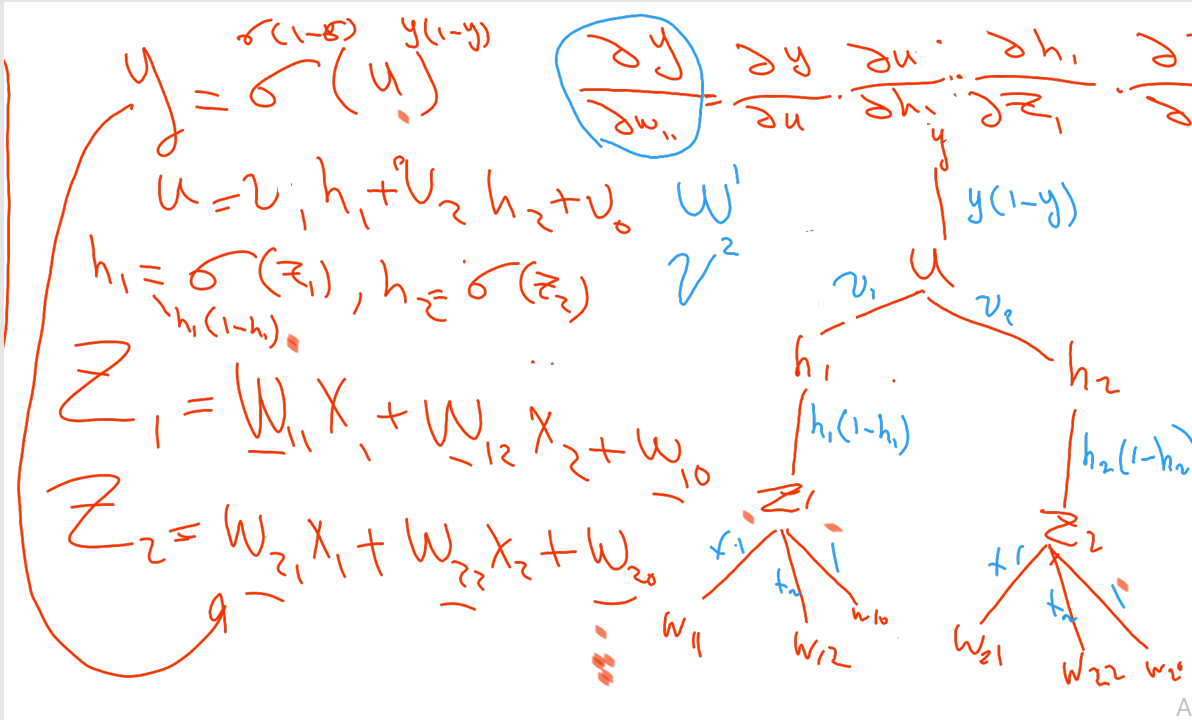

In [3]:
import torch

# X is (4, 2), we add a column of 1s to make it (4, 3)
x = torch.tensor([[0,0], [0,1], [1,0], [1,1]], dtype=torch.float32)
x_padded = torch.cat([x, torch.ones((4, 1))], dim=1) # Shape: (4, 3)
y = torch.tensor([[0], [1], [1], [0]], dtype=torch.float32)
learning_rate = 0.5


def sigmoid(z):
    return 1 / (1 + torch.exp(-z))

# 1. Init w (Padded X for bias)
# Hidden layer weights, one vector per layer (including bias)
# w(for layer 1): (3 inputs -> 2 neurons), 
# v(for layer 2): (3 hidden -> 1 output) 
w = torch.randn((3,2) ,dtype=torch.float32)
v = torch.randn((3,1) ,dtype=torch.float32)

for epoch in range(10000):
    # 2. Forward pass
    # Hidden layer
    Z_Hidden = x_padded @ w  
    H = sigmoid(Z_Hidden)

    
    # Remember to Pad the hidden layer output to account for v's bias
    H_padded = torch.cat([H, torch.ones((4, 1))], dim=1) 
    
    # Output layer
    Z_Output = H_padded @ v
    y_pred = sigmoid(Z_Output)

    loss = torch.mean((y_pred - y) ** 2)

    delta_o = (y_pred - y) * y_pred * (1 - y_pred)
    # Remember when to remove the bias element from the hidden layer output when backpropagating to w
    grad_v = H_padded.T @ delta_o

    # Backprop to hidden layer
    v_no_bias = v[:-1, :]
    delta_h = (delta_o @ v_no_bias.T) * H * (1 - H)
    grad_w = x_padded.T @ delta_h
    
    # v_new = v_old - learning_rate * grad_v
    w = w - learning_rate * grad_w
    v = v - learning_rate * grad_v

    # 6. Repeat until convergence
    if epoch % 2000 == 0:
        print(f"Epoch {epoch}, Loss: {loss.item():.4f}")

print("\nFinal Predictions (Padded Method):")
print(y_pred)

Epoch 0, Loss: 0.2961
Epoch 2000, Loss: 0.0023
Epoch 4000, Loss: 0.0008
Epoch 6000, Loss: 0.0005
Epoch 8000, Loss: 0.0004

Final Predictions (Padded Method):
tensor([[0.0168],
        [0.9843],
        [0.9808],
        [0.0150]])


In the saved run, the network predicted approximately 0.017, 0.984, 0.981, and 0.015 for the four XOR inputs.